[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/2_compute_g.ipynb)

# Compute G(x): train the diffusion model and run the pipeline

* **Goal**: take an encoder, train the diffusion model that the multi-scale Fisher metric G(x) needs, and compute G(x) and the Fisher information J(x) with the package's pipeline, then plot them.
* **The idea**: G(x) integrates the Fisher information of the stimulus over all scales of blur. It is estimated with a conditional diffusion model of the images given the neural responses, so the diffusion model is trained on pairs (image, response) where the **responses are predicted by the encoder**. Any encoder that follows the encoder contract can be plugged in.
* **Steps**: (1) load the encoder and predict responses to many images, (2) set up and train a small diffusion model, (3) compute G(x) and J(x), (4) plot, (5) compare with the ground truth of notebook 1.
* **Needs**: notebook 1 run once (it saves the encoder in `runs/getting_started/`), TinyImageNet in `data/tiny-imagenet-200`, and `diffusers`. A GPU is strongly recommended.
* **Execution time**: about 2 min on a GPU with the settings below. The paper trains a 68 M-parameter model for 200 epochs on 100,000 images (about 30 GPU-hours): the model here is tiny, so its G(x) is rough, and this notebook shows the workflow, not the quality of the paper's figures (notebook 3 does that, from the paper's checkpoints).

## 1. Setup and parameters

In [ ]:
# on Google Colab the package is not installed yet: install it (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q multigeom

In [ ]:
# move to the repository root (the folder containing environment.yml): data/ and runs/ are read from there
import os
from pathlib import Path

root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent
if (root / "environment.yml").exists():
    os.chdir(root)
print("working folder:", Path.cwd())

import time

import matplotlib.pyplot as plt
import numpy as np
import torch

import multigeom
from multigeom import compute_fisher, compute_g, load_encoder, subspace_alignment
from multigeom.config import load_config
from multigeom.data import GaborTeacher, TinyImageNetDataset
from multigeom.diffusion import DiffusionConfig
from multigeom.diffusion.model import build_diffusion_model, build_scheduler
from multigeom.diffusion.responses import precompute_responses
from multigeom.diffusion.train import train_diffusion
from multigeom.utils import make_generator

device = "cuda" if torch.cuda.is_available() else "cpu"
dev = torch.device(device)
torch.manual_seed(0)

# parameters
SAVE_DIR = Path("runs/getting_started")
IMAGES_PER_CLASS = 100     # TinyImageNet images to train the diffusion model on (200 classes)
EPOCHS = 5
N_MC = 50                  # Monte-Carlo samples of the G(x) estimator (the paper uses 200)
TIMESTEP_STEP = 80         # spacing of the diffusion times in the integral over scales (the paper uses 40)
N_COMPARE = 10             # test images for the comparison with the ground truth
if device == "cpu":        # a few minutes on a CPU
    IMAGES_PER_CLASS, EPOCHS, N_MC, TIMESTEP_STEP, N_COMPARE = 10, 1, 10, 160, 3
print("multigeom", multigeom.__version__, "| device:", device)

## 2. Load the encoder and predict responses to many images

We load the encoder that notebook 1 saved. To use an encoder of the paper instead, replace the line by `encoder = load_encoder("inception", area="V1", device=device)`: everything below stays the same.

The diffusion model is trained on TinyImageNet images, a large set of natural images, together with the responses **predicted by the encoder**: `precompute_responses(encoder, images)` is the batched `encoder.predict`.

In [2]:
encoder_path = SAVE_DIR / "encoder.pt"
if not encoder_path.exists():
    raise FileNotFoundError(f"{encoder_path} not found: run notebook 1 first, or load an encoder of the paper: "
                            "load_encoder('inception', area='V1')")
encoder = load_encoder(encoder_path, device=device)
print(encoder.summary())

dataset = TinyImageNetDataset("train", images_per_class=IMAGES_PER_CLASS)
images = torch.stack([dataset[i] for i in range(len(dataset))])                  # [N, 1, 64, 64] in [-1, 1]
t0 = time.time()
responses = precompute_responses(encoder, images, batch_size=512, device=device)
print(f"{len(images)} images -> responses {tuple(responses.shape)} in {time.time() - t0:.1f} s; "
      f"mean {responses.mean():.2f}, std {responses.std():.2f}")

NeuralEncoder: backbone SmallCNNBackbone (out [C=64, 16, 16]), readout GaussianReadout, 50 neurons, 59,976 trainable / 59,976 parameters
20000 images -> responses (20000, 50) in 0.9 s; mean 1.29, std 0.66


## 3. Set up the diffusion model

The diffusion configuration is shared by all encoders, except for the width of the first layer of the conditioning network, which is the number of neurons: `DiffusionConfig.for_encoder(encoder)` sets it. We then shrink the model and the recipe so that it trains in about a minute; the table shows the differences with the paper.

| | paper | here |
|---|---|---|
| UNet channels, layers per block | (64, 128, 256, 512), 2 | (32, 64, 128, 128), 1 |
| conditioning width | 256 | 64 |
| training images, epochs, batch | 100,000, 200, 128 | `IMAGES_PER_CLASS` x 200, `EPOCHS`, 64 |

The noise sigma of the observation model (0.22) must be the same in the diffusion model and in the estimator; both read it from the packaged configuration.

In [3]:
cfg = DiffusionConfig.for_encoder(encoder)                 # conditioning input width = number of neurons
cfg.unet.block_channels = [32, 64, 128, 128]
cfg.unet.layers_per_block = 1
cfg.unet.cross_attention_dim = 64
cfg.conditioning.mlp_layers = [encoder.n_neurons, 64, 64, 64]
cfg.train.epochs, cfg.train.batch_size, cfg.train.lr, cfg.train.warmup_steps = EPOCHS, 64, 3e-4, 100

model = build_diffusion_model(cfg)
print(f"diffusion model: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters "
      f"(the paper's: 68 M) | noise sigma {cfg.conditioning.observation_noise_sigma}")
del model

diffusion model: 5.5 M parameters (the paper's: 68 M) | noise sigma 0.22


## 4. Train the diffusion model

`train_diffusion(cfg, images, responses, out_dir)` trains the model to predict the noise added to the images, given the (noisy) responses, with classifier-free guidance dropout so that the same network also gives the unconditional prediction. It writes `final_model.pt` after every epoch and can resume an interrupted run (`resume=True`).

trained for 5 epochs in 105 s | loss 0.151 -> 0.070


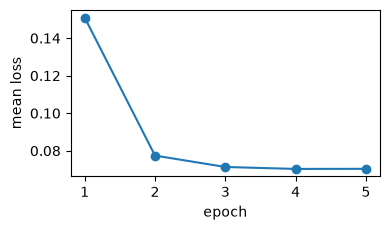

In [4]:
t0 = time.time()
history = train_diffusion(cfg, images, responses, SAVE_DIR / "diffusion", device=device, num_workers=0, save_every=1000, log=None)
print(f"trained for {EPOCHS} epochs in {time.time() - t0:.0f} s | loss {history['loss'][0]:.3f} -> {history['loss'][-1]:.3f}")

plt.figure(figsize=(4, 2.4)); plt.plot(history["epoch"], history["loss"], "o-")
plt.xlabel("epoch"); plt.ylabel("mean loss"); plt.tight_layout(); plt.show()

## 5. Compute G(x) and J(x)

We load the trained model and compute, for test images that the diffusion model never saw, the leading eigenvectors of

* the multi-scale Fisher metric G(x), with `compute_g` (the conditional-pair estimator of the paper: Monte-Carlo samples at every diffusion time, noise-prediction differences for two responses sampled around the encoder's prediction, then an SVD);
* the Fisher information J(x), with `compute_fisher` (closed form from the encoder's Jacobian).

Both take the image, the encoder and settings; `compute_g` also takes the diffusion model and its noise schedule.

In [ ]:
unet = build_diffusion_model(cfg).to(dev)
unet.load_state_dict(torch.load(SAVE_DIR / "diffusion" / "final_model.pt", map_location=dev, weights_only=False)["model_state_dict"])
unet.eval()
alphas_cumprod = build_scheduler(cfg).alphas_cumprod.to(dev)

est = load_config("estimator")                      # the packaged settings of the estimator
est.monte_carlo.n_samples = N_MC
est.monte_carlo.timestep_grid.step = TIMESTEP_STEP
est.top_k = 20
sigma = float(est.monte_carlo.observation_noise_sigma)

test_images = torch.stack([TinyImageNetDataset("val")[i] for i in range(N_COMPARE)])      # TinyImageNet validation images
G, J = [], []
t0 = time.time()
for i, x in enumerate(test_images):
    x = x.unsqueeze(0).to(dev)
    G.append(compute_g(image=x, encoder=encoder, unet=unet, alphas_cumprod=alphas_cumprod, cfg=est, device=dev,
                       generator=make_generator(int(est.seed) + i, dev)))
    J.append(compute_fisher(image=x, encoder=encoder, sigma=sigma, top_k=20, device=dev))
print(f"G(x) and J(x) for {len(test_images)} images in {time.time() - t0:.1f} s")
print("leading eigenvalues of G(x), image 0:", [f"{v:.3g}" for v in G[0].eigenvalues[:4].tolist()])
print("leading eigenvalues of J(x), image 0:", [f"{v:.3g}" for v in J[0].eigenvalues[:4].tolist()])

## 6. Plot

The leading eigenvectors of each metric (red positive, blue negative; the sign is arbitrary). They show which image changes the encoder's population is most sensitive to, at the scale of the metric: G(x) at all scales, J(x) only at the finest one. This is the layout of the paper's Fig. 3E-F.

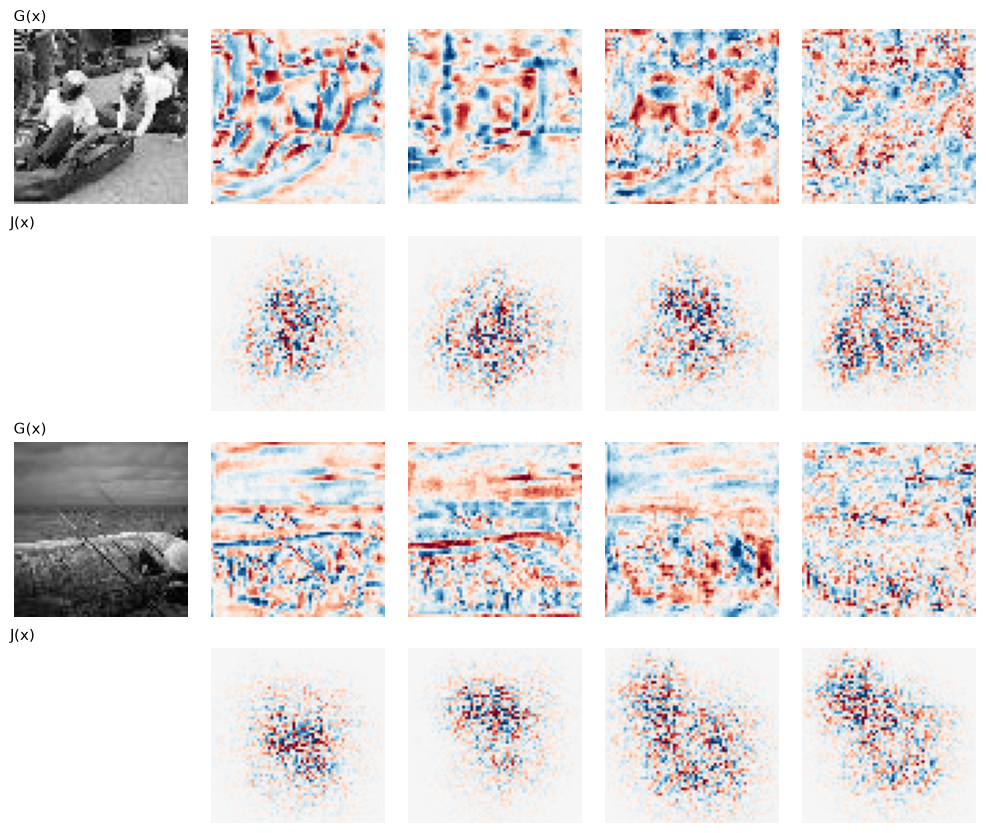

In [6]:
def show(ax, vec):
    v = vec.reshape(64, 64).cpu(); m = v.abs().quantile(0.99)
    ax.imshow(v, cmap="RdBu_r", vmin=-m, vmax=m); ax.axis("off")


n_show = min(2, len(test_images))
fig, axes = plt.subplots(2 * n_show, 5, figsize=(10, 4.2 * n_show))
for i in range(n_show):
    for r, (label, out) in enumerate([("G(x)", G[i]), ("J(x)", J[i])]):
        row = 2 * i + r
        axes[row, 0].imshow(test_images[i, 0], cmap="gray", vmin=-1, vmax=1) if r == 0 else None
        axes[row, 0].axis("off"); axes[row, 0].set_title(label, loc="left", fontsize=11)
        for k in range(4):
            show(axes[row, k + 1], out.eigenvectors[k])
plt.tight_layout(); plt.show()

## 7. Compare with the ground truth

The encoder was fitted to synthetic neurons whose true responses we know (the teacher of notebook 1). The subspace alignment $\mathcal{A}_k$ measures how much the top-k eigenvectors of two metrics span the same subspace (1 = identical, chance level = k / 4096). We compare the encoder's G(x) and J(x) with the teacher's J(x), averaged over the test images.

A caution on what this can show: the diffusion model here is tiny and briefly trained, there is one fitted encoder, and the teacher's own G(x) would need a diffusion model trained on the teacher's responses. The numbers say how close this small experiment gets, nothing more.

In [ ]:
saved = torch.load(SAVE_DIR / "teacher.pt", weights_only=False)
teacher = GaborTeacher(saved["n_neurons"], seed=saved["seed"]).to(dev)
teacher.load_state_dict(saved["state_dict"])
J_true = [compute_fisher(image=x.unsqueeze(0).to(dev), encoder=teacher, sigma=sigma, top_k=20, device=dev) for x in test_images]

print(f"subspace alignment with the ground-truth J(x), mean over {len(test_images)} images (chance = k / 4096):")
print(f"{'k':>3s} {'chance':>8s} {'J of the encoder':>18s} {'G of the encoder':>18s}")
for k in (1, 5, 10):
    a_j = np.mean([subspace_alignment(j.eigenvectors.cpu(), t.eigenvectors.cpu(), k) for j, t in zip(J, J_true)])
    a_g = np.mean([subspace_alignment(g.eigenvectors.cpu(), t.eigenvectors.cpu(), k) for g, t in zip(G, J_true)])
    print(f"{k:3d} {k / 4096:8.4f} {a_j:18.3f} {a_g:18.3f}")

## Recap and next steps

| To do | Call |
|---|---|
| responses of an encoder to many images | `precompute_responses(encoder, images)` |
| diffusion configuration for an encoder | `DiffusionConfig.for_encoder(encoder)` |
| train the diffusion model | `train_diffusion(cfg, images, responses, out_dir)` |
| multi-scale Fisher metric G(x) | `multigeom.compute_g(image=x, encoder=encoder, unet=unet, alphas_cumprod=..., cfg=est, device=...)` |
| Fisher information J(x) | `multigeom.compute_fisher(image=x, encoder=encoder, sigma=0.22)` |
| similarity of two sets of eigenvectors | `multigeom.subspace_alignment(eigvecs_a, eigvecs_b, k)` |

The same steps, for many images and several encoders, are the command-line stages of the pipeline (`multigeom train-diffusion`, `multigeom compute-g`, `multigeom align`). **Next**: notebooks 3 to 6 reproduce the figures of the paper from its trained checkpoints.